# Chapter 9 - Estimating Auction Models

<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#9.2.2-Sealed-Bid-Simulation" data-toc-modified-id="9.2.2-Sealed-Bid-Simulation-1">9.2.2 Sealed Bid Simulation</a></span></li><li><span><a href="#9.2.4-Sealed-Bid-Estimator-in-Python" data-toc-modified-id="9.2.4-Sealed-Bid-Estimator-in-Python-2">9.2.4 Sealed Bid Estimator in Python</a></span></li><li><span><a href="#9.3.4-English-Auction-Estimator-in-Python" data-toc-modified-id="9.3.4-English-Auction-Estimator-in-Python-3">9.3.4 English Auction Estimator in Python</a></span></li><li><span><a href="#9.4.1-Timber-Data" data-toc-modified-id="9.4.1-Timber-Data-4">9.4.1 Timber Data</a></span></li><li><span><a href="#9.4.2-Sealed-Bid-Auctions" data-toc-modified-id="9.4.2-Sealed-Bid-Auctions-5">9.4.2 Sealed Bid Auctions</a></span></li><li><span><a href="#9.4.3-English-Auctions" data-toc-modified-id="9.4.3-English-Auctions-6">9.4.3 English Auctions</a></span></li><li><span><a href="#9.4.4-Comparing-Estimates" data-toc-modified-id="9.4.4-Comparing-Estimates-7">9.4.4 Comparing Estimates</a></span></li><li><span><a href="#9.5-Are-Loggers-Colluding?" data-toc-modified-id="9.5-Are-Loggers-Colluding?-8">9.5 Are Loggers Colluding?</a></span></li><li><span><a href="#9.5.4-Large-English-Auction-Estimator-in-Python" data-toc-modified-id="9.5.4-Large-English-Auction-Estimator-in-Python-9">9.5.4 Large English Auction Estimator in Python</a></span></li><li><span><a href="#9.5.5-Evidence-of-Collusion" data-toc-modified-id="9.5.5-Evidence-of-Collusion-10">9.5.5 Evidence of Collusion</a></span></li><li><span><a href="#9.5.7-Large-Sealed-Bid-Auction-Estimator-in-Python" data-toc-modified-id="9.5.7-Large-Sealed-Bid-Auction-Estimator-in-Python-11">9.5.7 Large Sealed Bid Auction Estimator in Python</a></span></li></ul></div>

## 9.2.2 Sealed Bid Simulation

In [1]:
# as in the other chapters, we use numpy
import numpy as np

In [2]:
# remove Python warnings
import warnings
warnings.filterwarnings("ignore")

In [3]:
# setting the seed in Numpy
# the random numbers of Python are not the ones of R,
# so our results are close to the book but not the same
np.random.seed(123456789)

# pandas to store the simulated auctions in a dataframe
import pandas as pd

M = 1000  # number of simulated auctions.

# create an empty list to fill with one row per auction
rows = []

for i in range(0, M):

    # number of bidders, between 2 and 10.
    # np.round gives a decimal number (like 2.0)
    # and int() makes it a whole number
    N = int(np.round(np.random.uniform(low=2, high=10)))
    v = np.random.rand(N)  # valuations, uniform distribution.
    b = (N - 1)*v/N  # bid function
    p = np.max(b)  # auction price

    # bid data
    # a vector of 10 missing values (NA in R, np.nan in Python)
    # the first N are replaced by the bids
    x = np.full(10, np.nan)
    x[0:N] = b

    # one row with the number of bidders, the price and the 10 bids
    rows.append([N, p] + list(x))

# stacking all the auctions in a single dataframe
data1 = pd.DataFrame(rows, columns=['Num', 'Price', 'Bid1',
                                    'Bid2', 'Bid3', 'Bid4',
                                    'Bid5', 'Bid6', 'Bid7',
                                    'Bid8', 'Bid9', 'Bid10'])

In [4]:
# one row per auction
# the bidders are not listed in order
data1.head()

,Num,Price,Bid1,Bid2,Bid3,Bid4,Bid5,Bid6,Bid7,Bid8,Bid9,Bid10
0,6,0.736566,0.445114,0.424628,0.594637,0.214166,0.627245,0.736566,NaN,NaN,NaN,NaN
1,3,0.482418,0.447031,0.428963,0.482418,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,8,0.716229,0.716229,0.085670,0.003110,0.201958,0.010723,0.309349,0.162121,0.693672,NaN,NaN
3,7,0.840222,0.770939,0.270315,0.348562,0.840222,0.464627,0.207681,0.216207,NaN,NaN,NaN
4,7,0.839975,0.114289,0.751079,0.411713,0.242851,0.764752,0.709399,0.839975,NaN,NaN,NaN


## 9.2.4 Sealed Bid Estimator in Python

In [5]:
def sealed_2bid(bids, eps=0.5):
    """
    Values of the bidders in sealed bid auctions with two bidders
    * bids is a vector with all the bids
    * eps for "small" number for finite difference method
      of taking numerical derivatives.
    """
    values = np.zeros(len(bids))
    for i in range(0, len(bids)):
        # bid probability distribution
        # the mean of a True/False vector is the share of True
        H_hat = np.mean(bids < bids[i])
        # bid density
        h_hat = (np.mean(bids < bids[i] + eps) -
                 np.mean(bids < bids[i] - eps))/(2*eps)
        values[i] = bids[i] + H_hat/h_hat
    return values

In [6]:
# we keep the auctions with two bidders
# and the two columns where their bids are
bids = data1.loc[data1['Num']==2, ['Bid1', 'Bid2']]

# all the bids in a single vector
bids = np.array(bids).flatten()

values = sealed_2bid(bids)

The book says that the true density of the values lies at 0.5. The density of a uniform distribution between 0 and 1 is 1, so we draw the line at 1. The estimated values go up to 1.5 and not to 1, because eps = 0.5 is too large for these bids: they are all between 0 and 0.5, so h_hat is always 1 when the true density of the bids is 2.

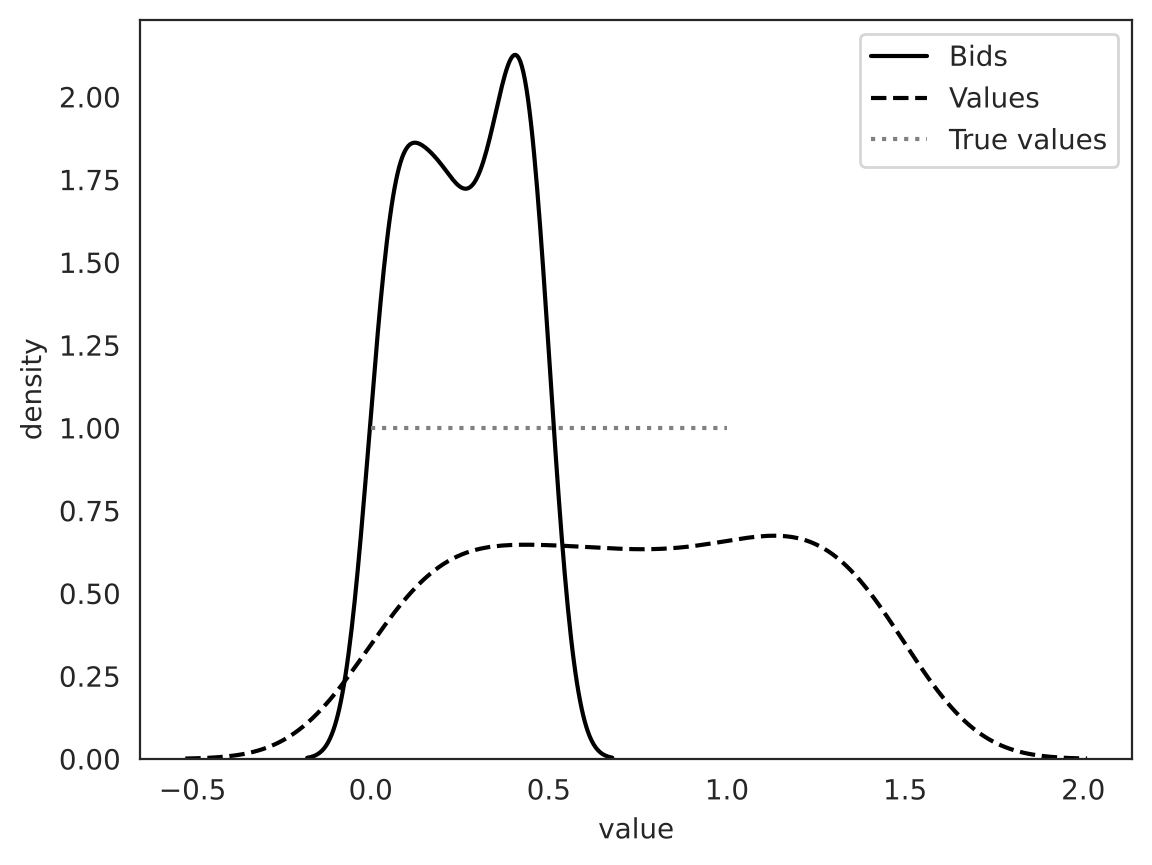

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# to have a R-looking plotting style
sns.set_style('white')

# density of the bids and of the estimated values
# sns.kdeplot is the equivalent of density() in R
sns.kdeplot(bids, color='k', label='Bids')
sns.kdeplot(values, color='k', linestyle='--', label='Values')

# true density of the values: 1 between 0 and 1
plt.hlines(1, 0, 1, colors='grey', linestyles=':', label='True values')

plt.xlabel('value')
plt.ylabel('density')
plt.legend()
plt.show()

## 9.3.4 English Auction Estimator in Python

In [8]:
def english_2bid(price, K=100, eps=1e-8):
    """
    Distribution of the values in English auctions with two bidders
    * price is a vector with the price of each auction
    * K number of finite values.
    * eps small number for getting the probabilities
      calculated correctly.
    * returns a matrix with K rows: the value in the first column
      and the probability to be below this value in the second column
    """
    min1 = np.min(price)
    max1 = np.max(price)
    diff1 = (max1 - min1)/K
    Fv = np.zeros((K, 2))

    # determines the boundaries of the cell.
    min_temp = min1 - eps
    max_temp = min_temp + diff1

    # python starts counting at 0: row 0 is the first cell,
    # column 0 is the value and column 1 is the probability
    Fv[0, 0] = (min_temp + max_temp)/2
    # price probability
    gp = np.mean((price > min_temp) & (price < max_temp))
    Fv[0, 1] = gp/2  # initial probability

    for k in range(1, K):
        min_temp = max_temp - eps
        max_temp = min_temp + diff1
        Fv[k, 0] = (min_temp + max_temp)/2
        gp = np.mean((price > min_temp) & (price < max_temp))
        # cumulative probability
        Fv[k, 1] = gp/(2*(1 - Fv[k-1, 1])) + Fv[k-1, 1]

    return Fv

In [9]:
# simulated data from an English auction
M = 10000

rows = []

for i in range(0, M):

    N = int(np.round(np.random.uniform(low=2, high=10)))
    v = np.random.normal(size=N)  # normally distributed values
    b = v  # bid

    # auction price: the second highest bid
    # -np.sort(-b) sorts the bids from the highest to the lowest
    # and [1] is the second one, as python starts counting at 0
    p = -np.sort(-b)[1]

    rows.append([N, p])

data2 = pd.DataFrame(rows, columns=['Num', 'Price'])

In [10]:
# the data set has the number of bidders and the price of each auction
data2.head()

,Num,Price
0,10,0.738290
1,10,1.042503
2,5,-0.293819
3,6,0.662007
4,7,0.262373


In [11]:
# restricts the data to auctions w/ 2 bidders.
price = np.array(data2.loc[data2['Num']==2, 'Price'])

Fv = english_2bid(price)

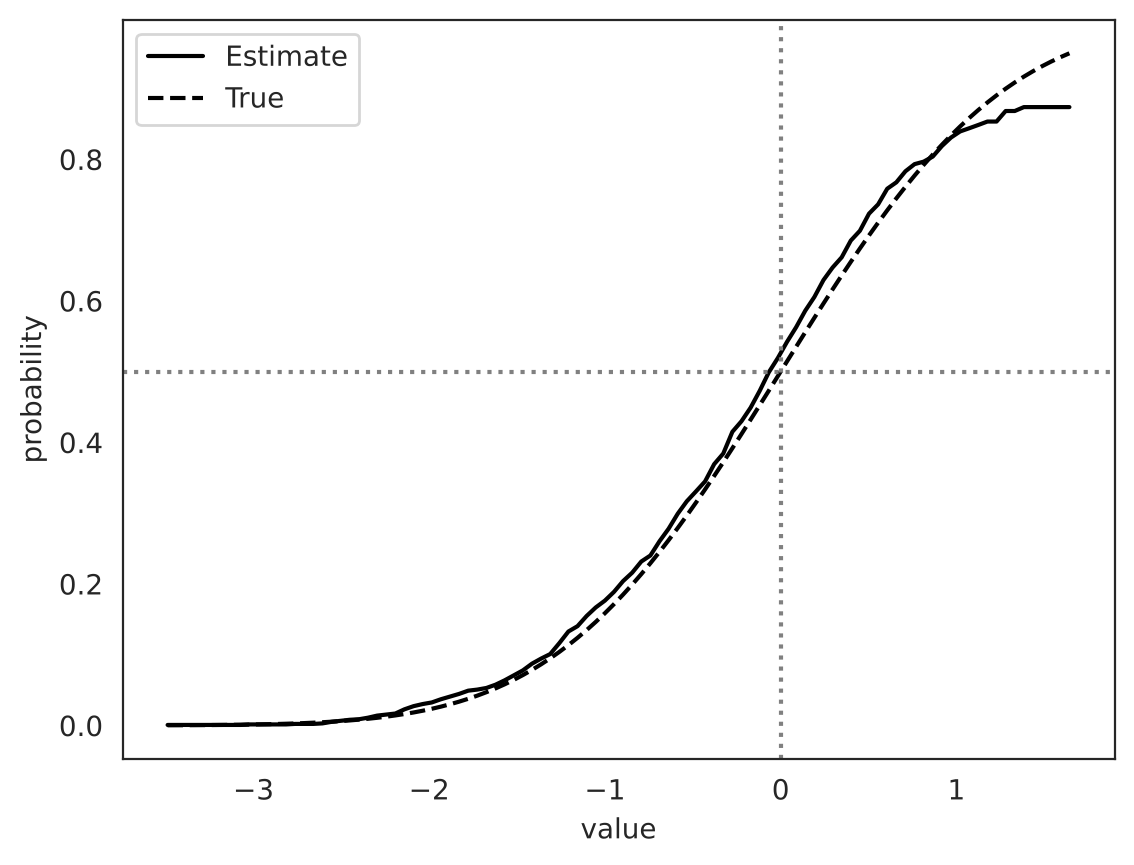

In [12]:
from scipy import stats

# estimated distribution of the values
plt.plot(Fv[:, 0], Fv[:, 1], color='k', label='Estimate')

# true distribution: the standard normal
# stats.norm.cdf is pnorm in R
plt.plot(Fv[:, 0], stats.norm.cdf(Fv[:, 0]), color='k', linestyle='--', label='True')

# the true distribution has a median of 0,
# so it goes through the point where the two dotted lines cross
plt.axhline(0.5, color='grey', linestyle=':')
plt.axvline(0, color='grey', linestyle=':')

plt.xlabel('value')
plt.ylabel('probability')
plt.legend()
plt.show()

## 9.4.1 Timber Data

In [13]:
# the first column of the file has the row numbers of R
# we use it as the index of the dataframe
x = pd.read_csv('../data/auctions.csv', index_col=0)
x.head()

,AuctionID,Name,Rank,Region,Forest,District,Acres,Salvage,Method.of.Sale,Sale.Size,Species,Road.Construction,Haul,num_bidders,log_amount,log_value
1,2,GRANITE LUMBER CO.,1,1,2,1,3796,N,S,7,93,100,50,3,17.505846,10.100616
2,2,DEL CONNER LUMBER CO.,2,1,2,1,3796,N,S,7,93,100,50,3,17.480728,10.100616
3,2,F.H. STOLTZE LAND & LBR.,3,1,2,1,3796,N,S,7,93,100,50,3,17.456453,10.100616
4,3,F.H. STOLTZE LAND & LUMBE,1,1,2,1,1560,N,S,5,108,0,33,1,12.864111,10.100616
5,4,"F.H. STOLTZE L & L CO.,IN",1,1,2,2,2458,N,S,5,108,0,54,1,13.168751,10.201664


In [14]:
# using statsmodels, as in chapters 2 and 3
import statsmodels.formula.api as sm

# C() is as.factor() in R: it creates a dummy variable for each entry under the
# variable name. For example, it will have a dummy for each
# species in the data.
# Python does not accept a dot in the name of a variable in a formula,
# so the names with a dot go inside Q("")
lm1 = sm.ols(formula='log_amount ~ C(Salvage) + Acres + Q("Sale.Size") + log_value + Haul + Q("Road.Construction") + C(Species) + C(Region) + C(Forest) + C(District)', data=x).fit()

# the residuals are the difference
# between the model estimate and the observed outcome.
# the regression drops the rows with missing values (NAs)
# pandas uses the index to put each residual on its row,
# and the dropped rows get a missing value
x['norm_bid'] = lm1.resid

In [15]:
# number of rows used in the regression and number of rows in the data
print(int(lm1.nobs), len(x))

8916 8920


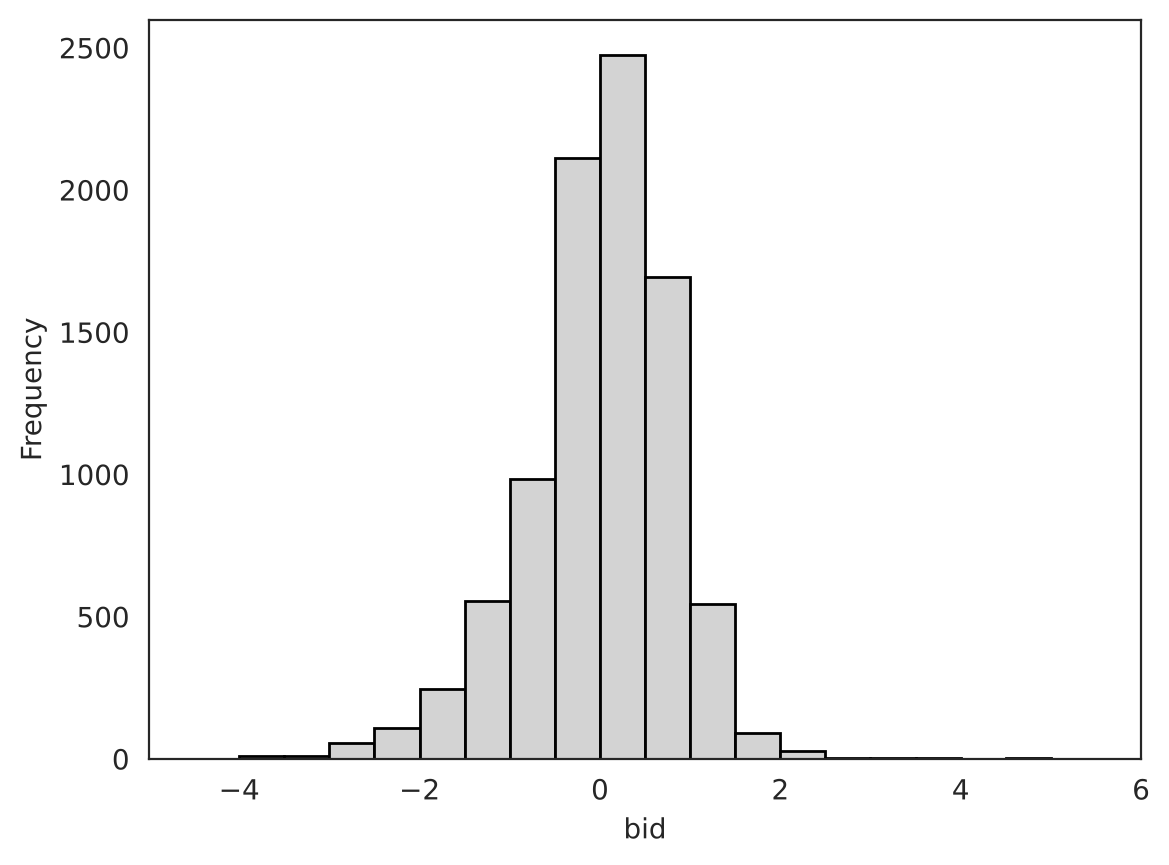

In [16]:
# histogram of the normalized log bids
# the missing values are removed first
# the bars are 0.5 wide, as in the book
plt.hist(x['norm_bid'].dropna(),
         bins=np.arange(-4.5, 6, 0.5),
         color='lightgrey',
         edgecolor='k')
plt.xlabel('bid')
plt.ylabel('Frequency')
plt.show()

## 9.4.2 Sealed Bid Auctions

In [17]:
# two-bidder auctions, sealed bid auctions are denoted "S"
y = x[(x['num_bidders']==2) & (x['Method.of.Sale']=='S')]

# we use a numpy array (and not a pandas column)
# to pick the bids by their position in the function
bids = np.array(y['norm_bid'])

values = sealed_2bid(bids)

In [18]:
# describe() is the summary() of R
# 25%, 50% and 75% are the 1st Qu., the Median and the 3rd Qu.
# we get the numbers of the book
pd.Series(bids).describe()

count    856.000000
mean      -0.241918
std        0.944304
min       -4.026185
25%       -0.798673
50%       -0.191844
75%        0.343734
max        5.064670
dtype: float64

In [19]:
# the values are higher than the bids, and more for the high bids
pd.Series(values).describe()

count    856.000000
mean       4.870437
std       37.097539
min       -4.026185
25%       -0.021760
50%        0.918546
75%        2.310759
max      860.064670
dtype: float64

## 9.4.3 English Auctions

In [20]:
# two-bidder auctions, English auctions are denoted "A"
y = x[(x['num_bidders']==2) & (x['Method.of.Sale']=='A')]

# the price is the second highest bid
price = np.array(y.loc[y['Rank']==2, 'norm_bid'])

Fv = english_2bid(price)

## 9.4.4 Comparing Estimates

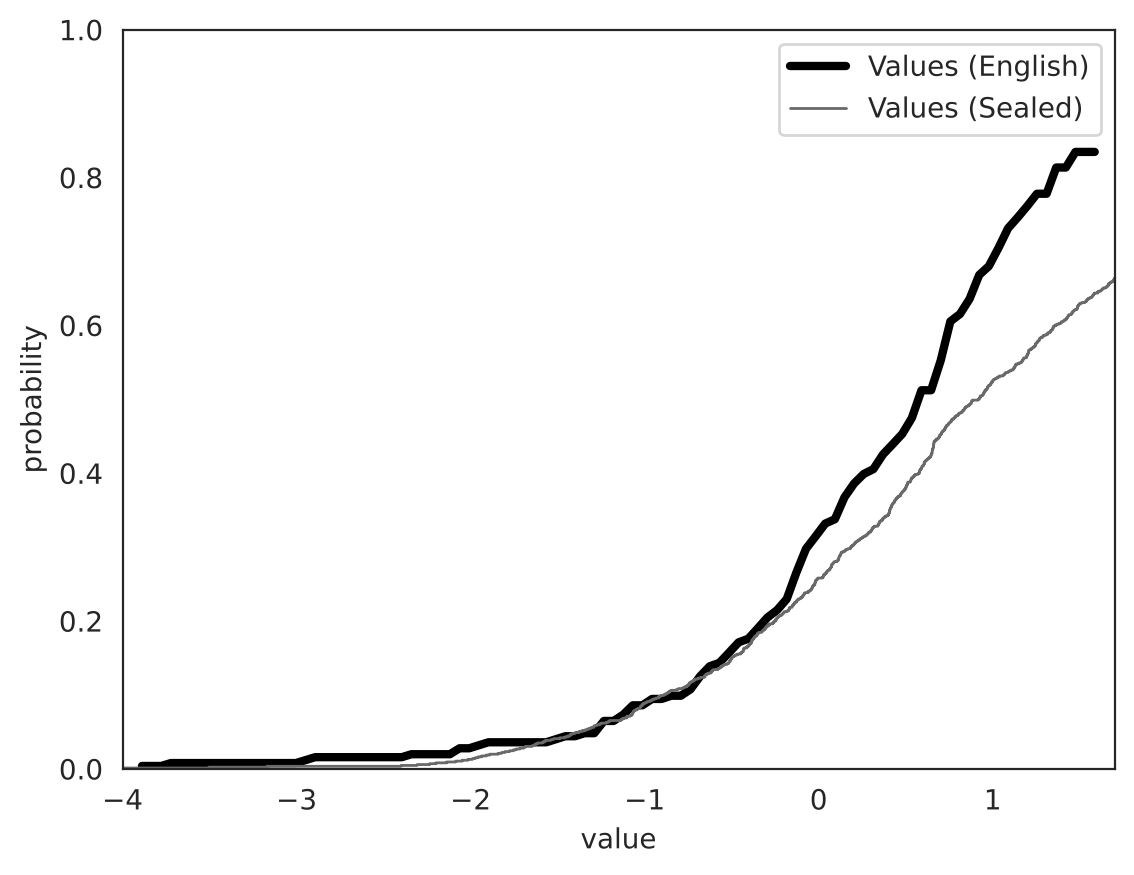

In [21]:
# distribution of the values from the English auctions
plt.plot(Fv[:, 0], Fv[:, 1], color='k', linewidth=3, label='Values (English)')

# distribution of the values from the sealed bid auctions
# sns.ecdfplot gives the share of the values below each number (ecdf() in R)
sns.ecdfplot(values, color='dimgray', linewidth=1, label='Values (Sealed)')

# a few values of the sealed bid auctions are very large (the maximum is 860)
# so we cut the horizontal axis
plt.xlim(-4, 1.7)
plt.xlabel('value')
plt.ylabel('probability')
plt.legend()
plt.show()

## 9.5 Are Loggers Colluding?

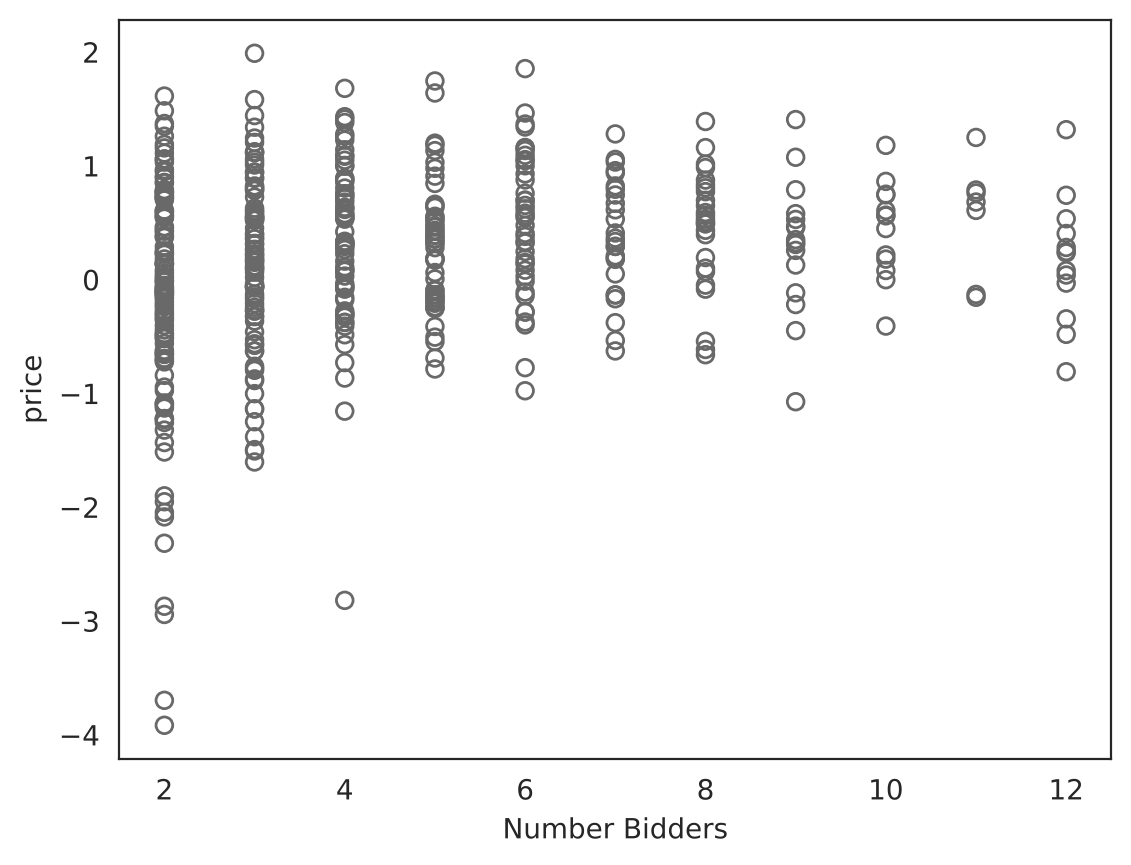

In [22]:
# all the English auctions
# we keep one row per auction, the bid of rank 2, which is the price
y_A = x[(x['Method.of.Sale']=='A') & (x['Rank']==2)]

# price against the number of bidders
plt.scatter(y_A['num_bidders'], y_A['norm_bid'], facecolors='none', color='dimgray')
plt.xlabel('Number Bidders')
plt.ylabel('price')
plt.show()

## 9.5.4 Large English Auction Estimator in Python

In [23]:
def english_Nbid(price, N, K=100, eps=1e-8):
    """
    Distribution of the values in English auctions with N bidders
    * same as english_2bid, with the formulas for N bidders
    * in Python ** means "to the power of" (^ in R)
    """
    min1 = np.min(price)
    max1 = np.max(price)
    diff1 = (max1 - min1)/K
    Fv = np.zeros((K, 2))

    min_temp = min1 - eps
    max_temp = min_temp + diff1
    Fv[0, 0] = (min_temp + max_temp)/2
    gp = np.mean((price > min_temp) & (price < max_temp))
    # initial probability
    Fv[0, 1] = (gp/N)**(1/(N-1))

    for k in range(1, K):
        min_temp = max_temp - eps
        max_temp = min_temp + diff1
        Fv[k, 0] = (min_temp + max_temp)/2
        gp = np.mean((price > min_temp) & (price < max_temp))
        # cumulative probability
        Fv[k, 1] = (gp/(N*(N-1)*(Fv[k-1, 1]**(N-2))*(1 - Fv[k-1, 1])) +
                    Fv[k-1, 1])

    return Fv

In [24]:
# English auctions with at least 6 bidders.
y2 = x[(x['num_bidders'] > 5) & (x['Method.of.Sale']=='A')]

price2 = np.array(y2.loc[y2['Rank']==2, 'norm_bid'])

# the same prices under three assumptions on the number of bidders
Fv6 = english_Nbid(price2, N=6)
Fv3 = english_Nbid(price2, N=3)
Fv2 = english_2bid(price2)

## 9.5.5 Evidence of Collusion

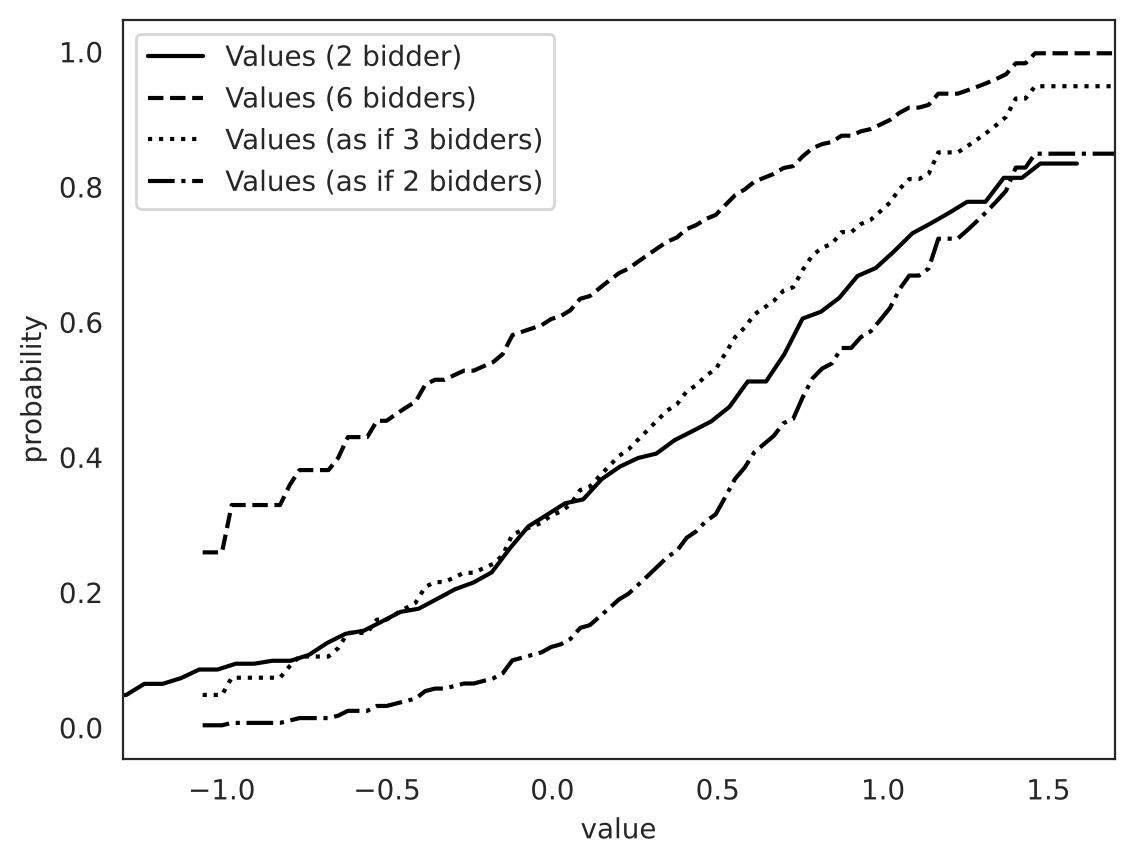

In [25]:
# estimate from the two-bidder auctions
plt.plot(Fv[:, 0], Fv[:, 1], color='k', label='Values (2 bidder)')

# estimates from the auctions with at least 6 bidders
plt.plot(Fv6[:, 0], Fv6[:, 1], color='k', linestyle='--', label='Values (6 bidders)')
plt.plot(Fv3[:, 0], Fv3[:, 1], color='k', linestyle=':', label='Values (as if 3 bidders)')
plt.plot(Fv2[:, 0], Fv2[:, 1], color='k', linestyle='-.', label='Values (as if 2 bidders)')

plt.xlim(-1.3, 1.7)
plt.xlabel('value')
plt.ylabel('probability')
plt.legend()
plt.show()

## 9.5.7 Large Sealed Bid Auction Estimator in Python

In [26]:
def sealed_Nbid(bids, N, eps=0.5):
    """
    Values of the bidders in sealed bid auctions with N bidders
    * same as sealed_2bid, with the probability of winning
      against N-1 other bidders
    """
    values = np.zeros(len(bids))
    for i in range(0, len(bids)):
        H_hat = np.mean(bids < bids[i])
        h_hat = (np.mean(bids < bids[i] + eps) -
                 np.mean(bids < bids[i] - eps))/(2*eps)
        # probability of winning the auction and its derivative
        G_hat = H_hat**(N-1)
        g_hat = (N-1)*h_hat*H_hat**(N-2)
        values[i] = bids[i] + G_hat/g_hat
    return values

In [27]:
# sealed bid auctions with at least 6 bidders.
y_6 = x[(x['num_bidders'] > 5) & (x['Method.of.Sale']=='S')]

bids_6 = np.array(y_6['norm_bid'])

values_6 = sealed_Nbid(bids_6, N=6, eps=3)

In [28]:
# for the lowest bid H_hat is 0, so the formula divides 0 by 0
# and its value is missing (NaN), in R as in Python
print(np.isnan(values_6).sum())

1


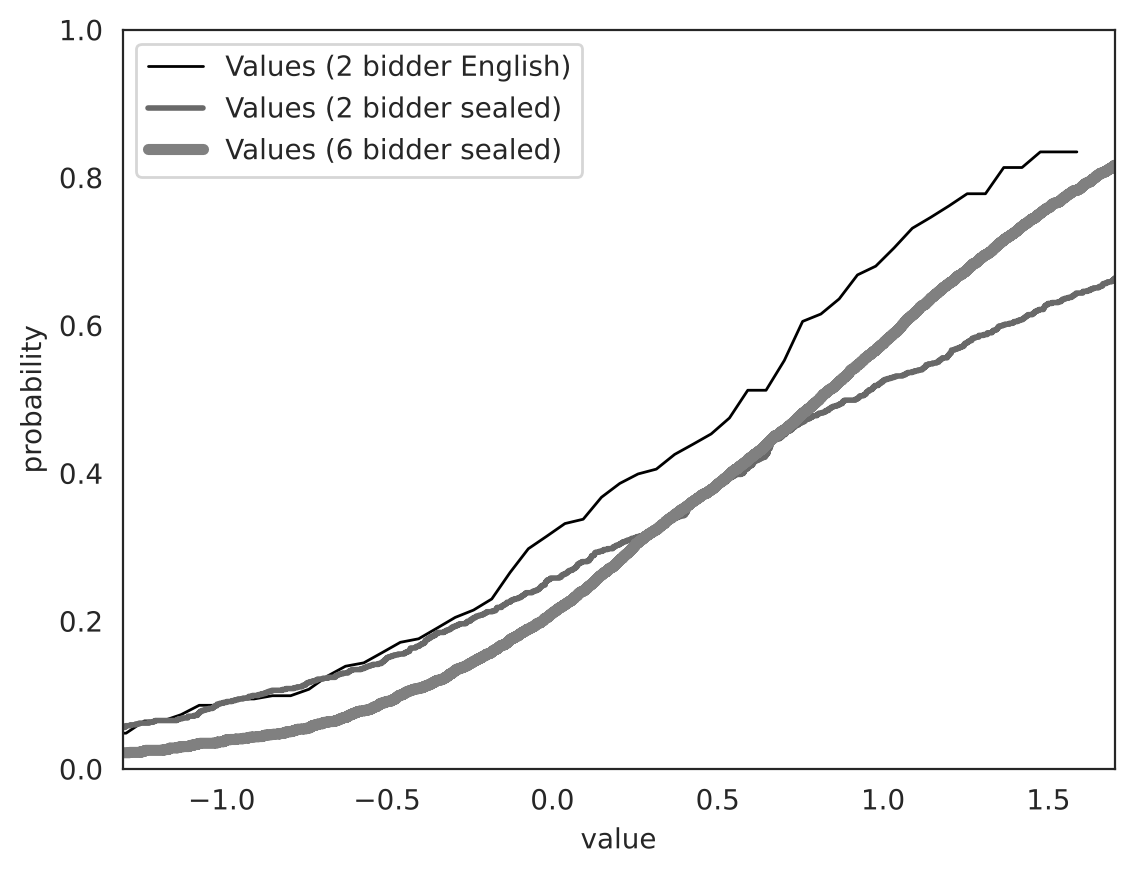

In [29]:
# estimate from the two-bidder English auctions
plt.plot(Fv[:, 0], Fv[:, 1], color='k', linewidth=1, label='Values (2 bidder English)')

# estimates from the sealed bid auctions, with two bidders and with at least 6
# sns.ecdfplot leaves the missing value out, as ecdf() does in R
sns.ecdfplot(values, color='dimgray', linewidth=2, label='Values (2 bidder sealed)')
sns.ecdfplot(values_6, color='grey', linewidth=4, label='Values (6 bidder sealed)')

plt.xlim(-1.3, 1.7)
plt.xlabel('value')
plt.ylabel('probability')
plt.legend()
plt.show()